# A ring attractor

$N$ ReLU neurons are placed on a ring, connected by a cosine kernel and given uniform
input. A bump of activity forms, with a height and width set by the input and the
coupling strength, and it stays wherever it is placed, so the network is a continuous
attractor. The model can be solved exactly, which lets us check the simulation against
the theory.

The model is a `RecurrentRateNetwork`: with all synaptic time constants at 0 it is the
voltage-form rate model $\tau \dot x = -x + W[x]_+ + b$. The weights come from theory
and aren't trained, so every connection is a `FrozenProjection`. Since wiretorch's
weights are non-negative, the signed cosine kernel is split across two cell types, as
explained below.

## The model

Place $N$ neurons at angles $\theta_i = 2\pi i / N$. The patterns $\mathbf c$ and
$\mathbf s$, with entries $\cos\theta_i$ and $\sin\theta_i$, are orthogonal with
$\mathbf c^\top \mathbf c = \mathbf s^\top \mathbf s = N/2$. The rank-2 matrix

$$
W = \frac{J}{N}\left(\mathbf c \mathbf c^\top + \mathbf s \mathbf s^\top\right),
\qquad W_{ij} = \frac{J}{N}\cos(\theta_i - \theta_j)
$$

has both patterns as eigenvectors with eigenvalue $J/2$, and 0 for every other mode
(the uniform mode included). It depends only on the angular distance between neurons:
nearby neurons excite each other, distant ones inhibit each other. The dynamics are

$$
\tau \dot{\mathbf x} = -\mathbf x + W[\mathbf x]_+ + b\,\mathbf 1 .
$$

## Wiring it with non-negative weights

wiretorch's weights are non-negative, the sign carried by the synapse type, so split
the kernel as $\cos\Delta = (1 + \cos\Delta) - 1$:

- the ring neurons excite each other with $\frac{J}{N}(1 + \cos(\theta_i - \theta_j))$;
- one inhibitory relay neuron, with $\tau_m = 0$ (it follows its input), reads out the
  mean ring rate $m = \frac1N \sum_j [x_j]_+$ and inhibits every ring neuron with
  weight $J$.

Each ring neuron then receives $\frac{J}{N}\sum_j(1+\cos(\theta_i-\theta_j))[x_j]_+ - Jm
= \sum_j W_{ij}[x_j]_+$: exactly $W$. The relay delays the uniform mode by one time
step, which is negligible for $dt \ll \tau$. Each ring neuron has its own input row, so the input
can carry $b$, cues and noise.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.optimize import brentq

import wiretorch as wt
from wiretorch import visualization as viz

viz.use_theme()  # the docs' plot style, light and dark

RING, INH = "ring", "global_inhibition"


@dataclass(frozen=True)
class RingParams:
    """N neurons, coupling J, uniform input b, time constant tau and step dt (ms)."""

    N: int = 128
    J: float = 3.0
    b: float = 1.0
    tau: float = 10.0
    dt: float = 0.5

    @property
    def angles(self) -> np.ndarray:
        return 2 * np.pi * np.arange(self.N) / self.N


def build(p: RingParams, batch_size: int = 1) -> wt.RecurrentRateNetwork:
    """The ring (neurons 0..N-1) and its inhibitory relay (neuron N)."""
    N, J, theta = p.N, p.J, p.angles
    delta = theta[:, None] - theta[None, :]
    rec = {  # (source, target) blocks
        (RING, RING): J / N * (1 + np.cos(delta)),  # excitatory
        (RING, INH): np.full((N, 1), 1 / N),  # excitatory: the relay reads m
        (INH, RING): np.full((1, N), J),  # inhibitory: -J m
    }
    return wt.RecurrentRateNetwork(
        dt=p.dt,
        rec_projections={
            k: wt.FrozenProjection(w.astype(np.float32)) for k, w in rec.items()
        },
        ff_projections={
            ("input", RING): wt.FrozenProjection(np.eye(N, dtype=np.float32))
        },
        cell_type_indices=np.array([0] * N + [1]),
        cell_type_indices_FF=np.zeros(N, dtype=np.int64),
        cell_params=[
            dict(name=RING, cell_id=0, tau_mem=p.tau, nonlinearity="relu"),
            dict(name=INH, cell_id=1, tau_mem=0.0, nonlinearity="relu"),
        ],
        cell_params_FF=[dict(name="input", cell_id=0)],
        synapse_params=[  # instantaneous synapses: the voltage form
            dict(name="exc", synapse_id=0, cell_id=0, tau_syn=0.0, type="excitatory"),
            dict(name="inh", synapse_id=1, cell_id=1, tau_syn=0.0, type="inhibitory"),
        ],
        synapse_params_FF=[
            dict(name="drive", synapse_id=0, cell_id=0, tau_syn=0.0, type="excitatory")
        ],
        batch_size=batch_size,
        track_variables=True,  # forward() returns voltages as well as rates
    )

## Check the wiring

The net ring-to-ring weights are the direct excitation minus the two-step path through
the relay. Read them off the built network and compare with $\frac JN\cos(\theta_i -
\theta_j)$, and check the spectrum: the cos/sin pair at $J/2$, everything else at 0.

largest difference from the cosine kernel: 1.820463616658552e-09
largest eigenvalues: [1.5 1.5 0. ]  J/2 = 1.5


<Figure size 550x330 with 1 Axes>
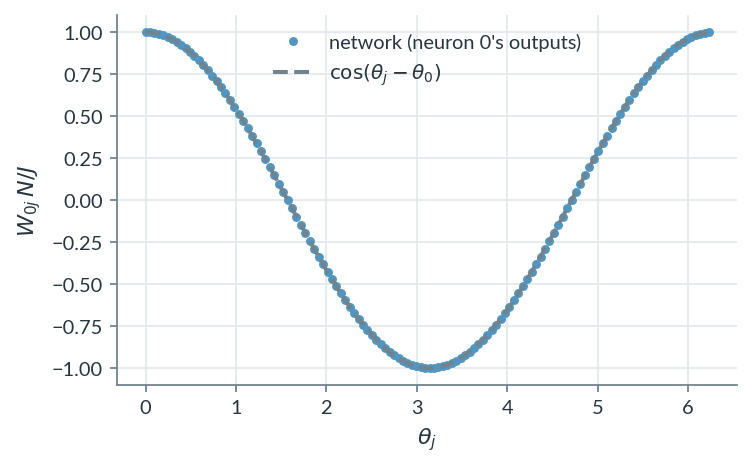
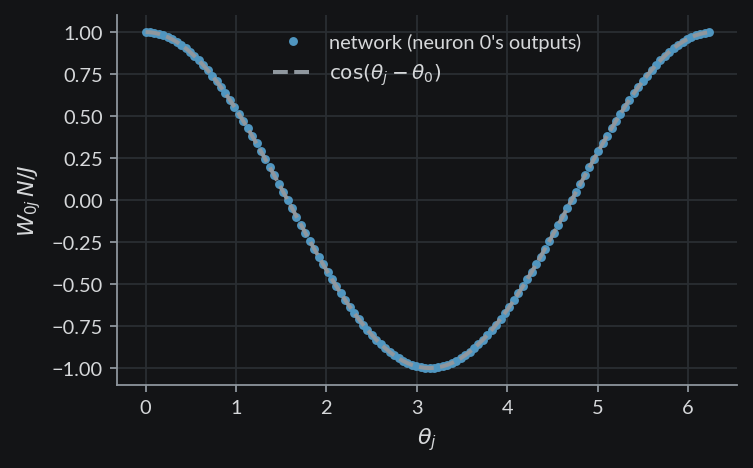

In [2]:
p = RingParams()
model = build(p)

W = model.weights.detach().cpu().numpy()  # (source, target), non-negative
N = p.N
W_net = W[:N, :N] - np.outer(W[:N, N], W[N, :N])  # direct minus through the relay
W_theory = p.J / N * np.cos(p.angles[:, None] - p.angles[None, :])
print("largest difference from the cosine kernel:", np.abs(W_net - W_theory).max())

eigenvalues = np.sort(np.linalg.eigvalsh(W_net))[::-1]
print("largest eigenvalues:", eigenvalues[:3].round(6), " J/2 =", p.J / 2)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(p.angles, W_net[0] * N / p.J, "o", ms=3, label="network (neuron 0's outputs)")
ax.plot(
    p.angles,
    np.cos(p.angles),
    "--",
    color=viz.theme.MUTED,
    label=r"$\cos(\theta_j - \theta_0)$",
)
ax.set_xlabel(r"$\theta_j$"), ax.set_ylabel(r"$W_{0j}\,N/J$"), ax.legend()
plt.show()

## Simulate, and read out the bump

`forward` takes the input $(B, T, N)$ and returns, with tracking on, the voltages and
rates of every step; the state carries over between calls. A bump-shaped state
$x_i = r\cos(\theta_i - \psi) + b$ is read out by the first Fourier coefficient
around the ring, $z = \frac2N\sum_i x_i e^{i\theta_i} = r e^{i\psi}$.

In [3]:
def set_state(model, x0):
    """Ring voltages x0 (B, N); the relay starts at the mean ring rate."""
    x0 = torch.as_tensor(np.atleast_2d(x0), dtype=torch.float32)
    relay = torch.relu(x0).mean(-1, keepdim=True)
    model.v = torch.cat([x0, relay], dim=-1).to(model.device)


def simulate(model, inputs, chunk=2000):
    """Run from the current state; returns ring voltages and rates (B, T, N)."""
    xs, rs = [], []
    with torch.no_grad():
        for s in range(0, inputs.shape[1], chunk):
            out = model(torch.as_tensor(inputs[:, s : s + chunk], dtype=torch.float32))
            xs.append(out["voltages"][..., :-1].cpu().numpy())  # drop the relay
            rs.append(out["rates"][..., :-1].cpu().numpy())
    return {"x": np.concatenate(xs, 1), "rates": np.concatenate(rs, 1)}


def uniform_input(p, batch, n_steps):
    return np.full((batch, n_steps, p.N), p.b, dtype=np.float32)


def project(x, angles):
    """Amplitude r and position psi of the cos/sin component of x (..., N)."""
    z = 2 / angles.size * (x * np.exp(1j * angles)).sum(-1)
    return np.abs(z), np.angle(z) % (2 * np.pi)

## A bump forms

For a small bump, $b$ keeps every neuron above threshold, nothing is clipped, and the
cos/sin modes grow with gain $J/2$: for $J > 2$ the uniform state is unstable. As the
bump grows, rectification clips more of the ring, and the gain of the clipped cosine
falls. Write the bump's half-width (the angle from its centre to its edges) as
$\theta_c$, with $\cos\theta_c = -b/r$; the clipped gain is

$$
\lambda(r) = J\,\frac{\theta_c - \sin\theta_c\cos\theta_c}{2\pi},
\qquad \tau\dot r = (\lambda(r) - 1)\,r ,
$$

so the amplitude grows while $\lambda > 1$ and stops where $\lambda(r^*) = 1$.
Start from the uniform state plus a little noise:

<Figure size 1210x385 with 3 Axes>
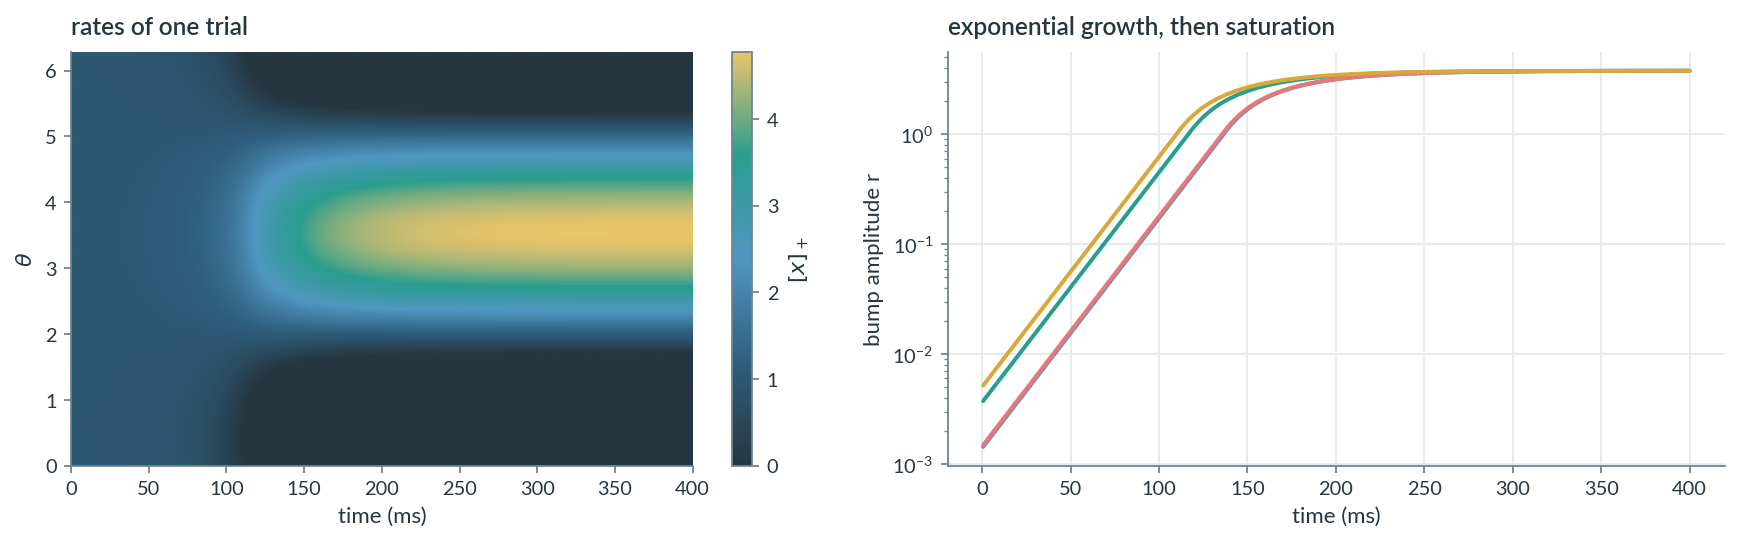
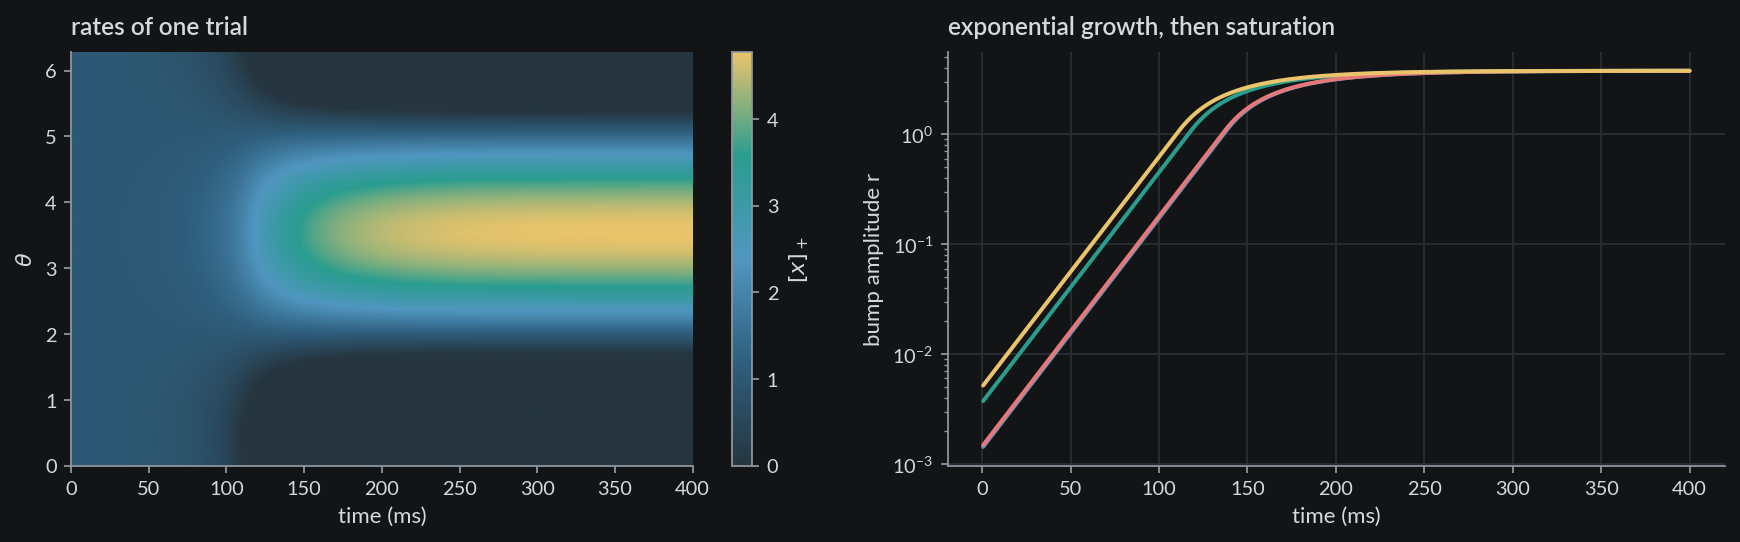

(None, None)

In [4]:
B, T = 4, 800  # 400 ms
model = build(p, batch_size=B)
rng = np.random.default_rng(1)
set_state(model, p.b + 0.02 * rng.standard_normal((B, p.N)))
out = simulate(model, uniform_input(p, B, T))
r, psi = project(out["x"], p.angles)
t = np.arange(1, T + 1) * p.dt

shown = np.argmin(np.abs(psi[:, -1] - np.pi))  # the trial whose bump ends nearest pi
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
im = a.imshow(
    out["rates"][shown].T,
    aspect="auto",
    origin="lower",
    cmap="wiretorch",
    extent=[0, t[-1], 0, 2 * np.pi],
)
a.set_xlabel("time (ms)"), a.set_ylabel(r"$\theta$"), a.set_title("rates of one trial")
fig.colorbar(im, ax=a, label=r"$[x]_+$")
b.semilogy(t, r.T)
b.set_xlabel("time (ms)"), b.set_ylabel("bump amplitude r")
b.set_title("exponential growth, then saturation")
plt.tight_layout(), plt.show()

## The fixed point: $J$ sets the width, $b$ the height

$\lambda(r^*) = 1$ depends only on the bump's shape, so it fixes the half-width from $J$
alone, and the amplitude then follows from the input:

$$
J(\theta_c - \sin\theta_c\cos\theta_c) = 2\pi, \qquad r^* = -\frac{b}{\cos\theta_c}.
$$

The half-width must lie between $\pi/2$ and $\pi$, so stable bumps need $2 < J < 4$.
Compare with simulations that have settled:

<Figure size 550x352 with 1 Axes>
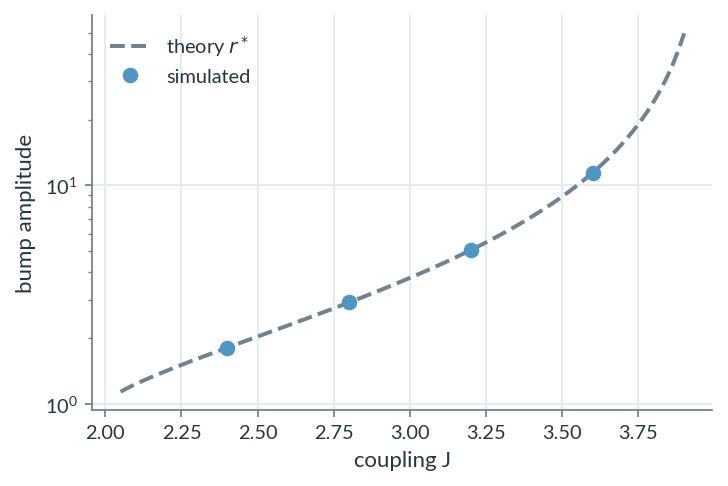
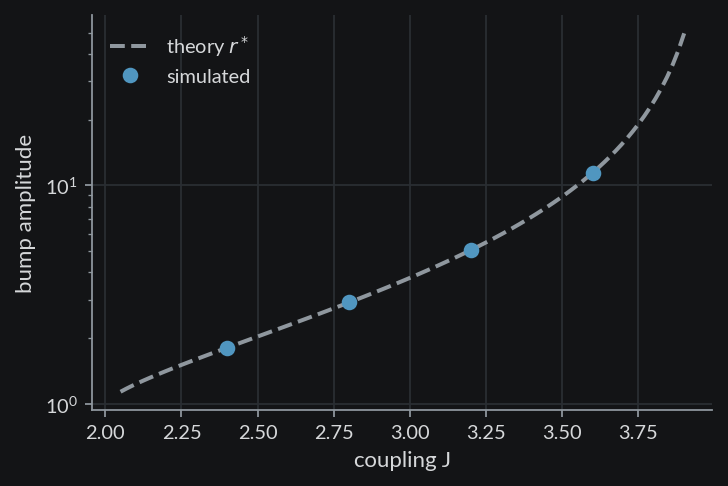

relative error: 0.00024240498241989705


In [5]:
def gain(theta_c, J):
    return J * (theta_c - np.sin(theta_c) * np.cos(theta_c)) / (2 * np.pi)


def fixed_half_width(J):
    return brentq(lambda th: gain(th, J) - 1, 1e-9, np.pi)


def fixed_amplitude(J, b):
    return -b / np.cos(fixed_half_width(J))


Js = [2.4, 2.8, 3.2, 3.6]
simulated, predicted = [], []
for J in Js:
    q = RingParams(J=J)
    m = build(q)
    set_state(m, q.b + 0.5 * np.cos(q.angles - 1.0))  # a small bump at psi = 1
    x_end = simulate(m, uniform_input(q, 1, 1600))["x"][0, -1]
    simulated.append(project(x_end, q.angles)[0])
    predicted.append(fixed_amplitude(J, q.b))

fine = np.linspace(2.05, 3.9, 100)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(
    fine,
    [fixed_amplitude(J, p.b) for J in fine],
    "--",
    color=viz.theme.MUTED,
    label=r"theory $r^*$",
)
ax.semilogy(Js, simulated, "o", label="simulated")
ax.set_xlabel("coupling J"), ax.set_ylabel("bump amplitude"), ax.legend()
plt.show()
print("relative error:", np.abs(np.array(simulated) / predicted - 1).max())

## A continuous attractor

The position obeys $\dot\psi = 0$: by the rotational symmetry of $W$, a bump centred
anywhere is a fixed point. Start bumps at eight positions and watch them stay:

<Figure size 550x352 with 1 Axes>
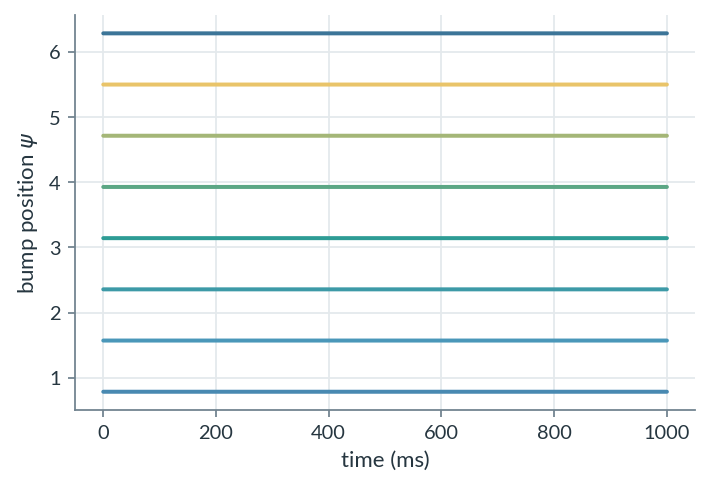
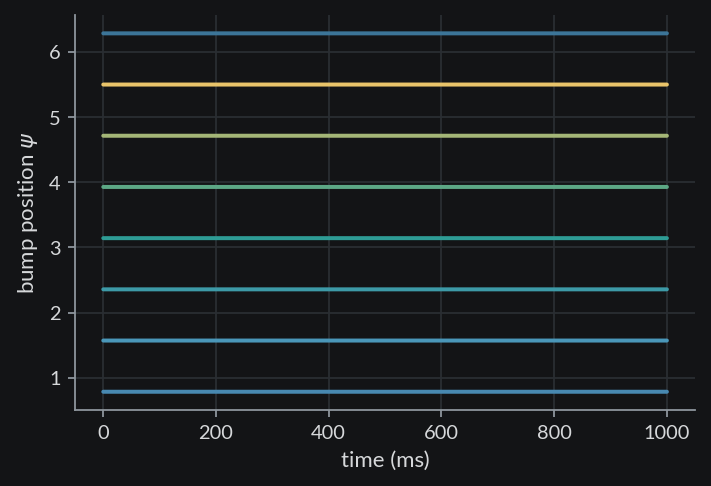

largest drift over 1 s (rad): 3.699378494877034e-07


In [6]:
starts = np.linspace(0, 2 * np.pi, 8, endpoint=False)
model = build(p, batch_size=starts.size)
r0 = fixed_amplitude(p.J, p.b)
set_state(model, r0 * np.cos(p.angles[None] - starts[:, None]) + p.b)
out = simulate(model, uniform_input(p, starts.size, 2000))  # 1 s
_, psi = project(out["x"], p.angles)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.set_prop_cycle(color=plt.get_cmap("wiretorch")(np.linspace(0.35, 1, 8)))
ax.plot(np.arange(1, 2001) * p.dt, psi.T)
ax.set_xlabel("time (ms)"), ax.set_ylabel(r"bump position $\psi$")
plt.show()
drift = np.angle(np.exp(1j * (psi[:, -1] - starts)))  # wrapped to (-pi, pi]
print("largest drift over 1 s (rad):", np.abs(drift).max())

## Summary

The eigenvalue $J/2 > 1$ of the cos/sin pair makes the uniform state unstable, so a bump
forms. Rectification then lowers the bump's effective gain until it equals 1, so the
amplitude is stable over a range of $J$ without fine tuning. $J$ sets the width and $b$
the height, and by rotational symmetry every position is a fixed point.

To fit a model like this to data, replace the projections with trainable ones
({doc}`../concepts/projections`) or learn its time constants with `learn=`.